# Analysis for Experiments 1 & 2 (Sanjay)

- **E1:** How does build cost grow with *n*? How much memory does each index use? (`track_id`, file order, 7 sizes from 1,000 to 114,000)
- **E2:** How does point-lookup cost grow with *n*, for hits and for misses? (`track_id`, same sizes, 500 queries per batch, hit rates 1.0 and 0.0)

Before-fix runs: E1 on `0a4ba73` (B+ tree fix only), E2 on `67f1780` (B+ tree and AVL fixes).
After-fix runs: both on `5deba04` (all four fixes: INC-01 to INC-04). An earlier post-fix run on `fdaa48d` is also in the CSV but was taken while the machine was busy (1.3 to 1.8x slower on indexes with no bug, identical counters), so it is not used here. Machine: `sanjay-mba`.

In [12]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

RESULTS = Path("..") / "results" / "timings.csv"
df = pd.read_csv(RESULTS)

# Per-operation cost: every row is a batch of n_ops operations.
df["us_per_op"] = df["total_ns"] / df["n_ops"] / 1_000   # microseconds per operation
for counter in ["comparisons", "nodes_visited", "rotations", "splits", "resizes"]:
    df[f"{counter}_per_op"] = df[counter] / df["n_ops"]

## Pick the rows: my machine, before vs after the fixes

Rows from before and after the bug fixes live in the same file, so filter on `code_version` and `machine_id` before comparing anything.

In [13]:
MACHINE = "sanjay-mba"
E1_BEFORE = "0a4ba73"   # B+ tree fix only
E2_BEFORE = "67f1780"   # B+ tree + AVL fixes
AFTER     = "5deba04"   # all fixes

mine = df[df["machine_id"] == MACHINE]
e1_all = mine[mine["experiment"] == "E1_build_track_id"].copy()
e2_all = mine[mine["experiment"] == "E2_point_lookup"].copy()

# Post-fix rows only: these are what the analysis and recommendations use.
e1 = e1_all[e1_all["code_version"] == AFTER]
e2 = e2_all[e2_all["code_version"] == AFTER]

# Sanity checks: every configuration has 5 reps, and nothing is "-dirty".
print(mine[mine["experiment"].isin(["E1_build_track_id", "E2_point_lookup"])]
      .groupby(["experiment", "code_version"]).size())
assert len(e1) == 7 * 7 * 5, len(e1)          # 7 sizes x 7 indexes x 5 reps
assert len(e2) == 7 * 7 * 2 * 5, len(e2)      # ... x 2 hit rates
assert not e1_all["code_version"].str.endswith("-dirty").any()
assert not e2_all["code_version"].str.endswith("-dirty").any()

experiment         code_version
E1_build_track_id  0a4ba73         245
                   5deba04         245
                   fdaa48d         245
E2_point_lookup    5deba04         490
                   67f1780         490
                   fdaa48d         490
dtype: int64


## Helper: log-log slope with a bootstrap interval

On log-log axes, cost proportional to $n^k$ is a straight line with slope $k$ (0 = constant, 1 = linear; $\log n$ shows up as a small positive slope).
To get an interval for $k$, resample the 5 replicates at each *n* with replacement, take the median at each *n*, refit, and repeat 1,000 times. The 2.5th and 97.5th percentiles of those slopes give a 95% interval.

In [14]:
def slope_ci(g, x="n_keys", y="us_per_op", B=1000, seed=0):
    """Log-log slope of median(y) vs x, with a 95% bootstrap interval over replicates."""
    rng = np.random.default_rng(seed)
    groups = [(n, gg[y].to_numpy(dtype=float)) for n, gg in g.groupby(x)]
    xs = np.log10([n for n, _ in groups])
    k = np.polyfit(xs, np.log10([np.median(v) for _, v in groups]), 1)[0]
    boots = [
        np.polyfit(xs, np.log10([np.median(rng.choice(v, len(v))) for _, v in groups]), 1)[0]
        for _ in range(B)
    ]
    lo, hi = np.percentile(boots, [2.5, 97.5])
    return round(k, 2), round(lo, 2), round(hi, 2)

## Distinct keys

`track_id` is **not** unique: a song appears once per genre it is listed under (89,741 distinct ids in 114,000 rows).
The sorted list, hash table, AVL tree and B+ tree store one entry per *distinct* key, so the theory lines below use the distinct count.

In [15]:
ids = pd.read_csv(Path("..") / "data" / "spotify_tracks.csv", usecols=["track_id"])["track_id"]
sizes = sorted(e1["n_keys"].unique())
distinct = {n: ids.iloc[:n].nunique() for n in sizes}
pd.Series(distinct, name="distinct track_ids").to_frame().assign(share_distinct=lambda t: (t.iloc[:, 0] / t.index).round(3))

,distinct track_ids,share_distinct
1000,1000,1.000
2000,1999,1.000
5000,4404,0.881
10000,9268,0.927
20000,18905,0.945
50000,44190,0.884
114000,89741,0.787


## Variability across replicates

Coefficient of variation (std / mean) of the 5 replicates for each configuration, then the median CV per index. This shows how noisy the timings are.

In [16]:
def cv_table(data, by):
    cv = data.groupby(by)["us_per_op"].agg(lambda s: s.std() / s.mean())
    return cv.groupby(level=0).median().round(3).rename("median CV")

display(cv_table(e1, ["index_type", "n_keys"]).to_frame("E1 build: median CV"))
display(cv_table(e2, ["index_type", "operation", "n_keys"]).to_frame("E2 lookup: median CV"))

,E1 build: median CV
index_type,
avl_tree,0.018
bplus_tree,0.027
hash_table,0.032
ref_bisect,0.028
ref_dict,0.060
sorted_list,0.049
unsorted_list,0.081


,E2 lookup: median CV
index_type,
avl_tree,0.035
bplus_tree,0.034
hash_table,0.071
ref_bisect,0.053
ref_dict,0.066
sorted_list,0.081
unsorted_list,0.028


# E1: Build cost

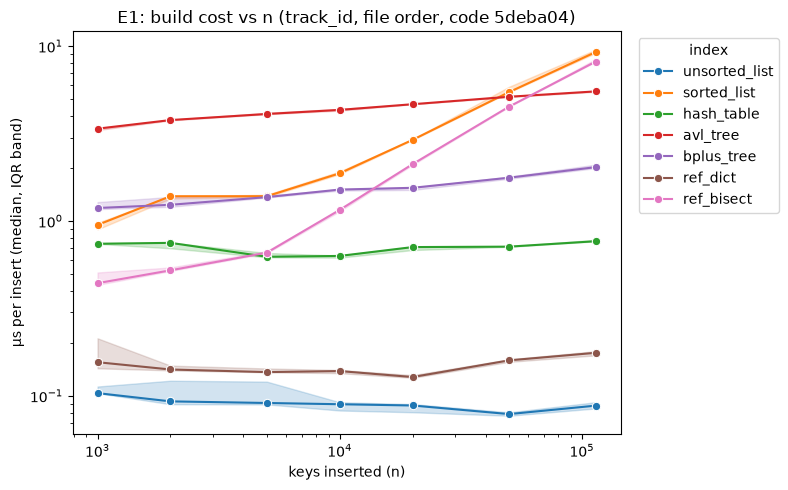

In [17]:
fig, ax = plt.subplots(figsize=(8, 5))
sns.lineplot(data=e1, x="n_keys", y="us_per_op", hue="index_type",
             estimator="median", errorbar=("pi", 50), marker="o", ax=ax)
ax.set(xscale="log", yscale="log", xlabel="keys inserted (n)",
       ylabel="µs per insert (median, IQR band)",
       title=f"E1: build cost vs n (track_id, file order, code {AFTER})")
ax.legend(title="index", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.savefig("e1_build_postfix.png", dpi=150)
plt.show()

### Medians and IQR per insert

In [18]:
(e1.groupby(["index_type", "n_keys"])["us_per_op"]
   .describe(percentiles=[0.25, 0.5, 0.75])[["25%", "50%", "75%"]]
   .rename(columns={"50%": "median"}).round(3)
   .unstack("n_keys")["median"])

n_keys,1000,2000,5000,10000,20000,50000,114000
index_type,,,,,,,
avl_tree,3.370,3.774,4.090,4.316,4.651,5.131,5.507
bplus_tree,1.186,1.237,1.368,1.512,1.547,1.767,2.031
hash_table,0.740,0.749,0.624,0.631,0.709,0.713,0.766
ref_bisect,0.441,0.522,0.659,1.157,2.114,4.504,8.155
ref_dict,0.156,0.141,0.137,0.139,0.128,0.159,0.176
sorted_list,0.949,1.385,1.384,1.873,2.911,5.453,9.248
unsorted_list,0.104,0.093,0.091,0.089,0.088,0.079,0.088


### Slope of per-insert cost vs n

Expected: about 0 for hash table / `ref_dict` / unsorted list (O(1) amortized per insert); a small positive slope for the AVL and B+ trees (O(log n) per insert);
rising toward 1 for the sorted list and `ref_bisect` at large *n*, because every `list.insert` shifts the rest of the list (O(n) per insert, done by a C memmove).

In [19]:
e1_slopes = pd.DataFrame([(idx, *slope_ci(g)) for idx, g in e1.groupby("index_type")],
                         columns=["index", "k", "ci_lo", "ci_hi"]).sort_values("k")
e1_slopes

,index,k,ci_lo,ci_hi
6,unsorted_list,-0.04,-0.12,-0.02
2,hash_table,0.01,-0.00,0.02
4,ref_dict,0.03,-0.06,0.04
0,avl_tree,0.10,0.10,0.11
1,bplus_tree,0.11,0.09,0.12
5,sorted_list,0.47,0.46,0.49
3,ref_bisect,0.65,0.61,0.66


### Counters vs theory

- Hash table: a doubling table starting at 8 buckets with max load 0.75 needs $\lceil \log_2(d / (0.75 \cdot 8)) \rceil$ resizes for *d* distinct keys.
- AVL tree: height at most $1.44 \log_2(d + 2)$, and at most about one rotation per insert.
- B+ tree (order 32): height should be 3 to 4 at these sizes.

In [20]:
first = e1.groupby(["index_type", "n_keys"]).first().reset_index()   # counters are identical across reps
t = first[first["index_type"].isin(["hash_table", "avl_tree", "bplus_tree"])][
    ["index_type", "n_keys", "resizes", "rotations_per_op", "splits", "height"]].copy()
t["distinct"] = t["n_keys"].map(distinct)
t["doubling_resizes"] = np.ceil(np.log2(t["distinct"] / (0.75 * 8))).astype(int)
t["avl_height_bound"] = (1.44 * np.log2(t["distinct"] + 2)).round(1)
t.round(3)

,index_type,n_keys,resizes,rotations_per_op,splits,height,distinct,doubling_resizes,avl_height_bound
0,avl_tree,1000,0.0,0.718,0.0,12.0,1000,8,14.4
1,avl_tree,2000,0.0,0.704,0.0,13.0,1999,9,15.8
2,avl_tree,5000,0.0,0.614,0.0,14.0,4404,10,17.4
3,avl_tree,10000,0.0,0.648,0.0,16.0,9268,11,19.0
4,avl_tree,20000,0.0,0.668,0.0,17.0,18905,12,20.5
5,avl_tree,50000,0.0,0.620,0.0,19.0,44190,13,22.2
6,avl_tree,114000,0.0,0.551,0.0,20.0,89741,14,23.7
7,bplus_tree,1000,0.0,0.000,44.0,3.0,1000,8,14.4
8,bplus_tree,2000,0.0,0.000,93.0,3.0,1999,9,15.8
9,bplus_tree,5000,0.0,0.000,214.0,3.0,4404,10,17.4


# E1: Memory

`memory_bytes` is measured once per (index, n) while building. Expect it to grow in proportion to *n* (slope about 1) for every index.

In [21]:
mem = e1.groupby(["index_type", "n_keys"])["memory_bytes"].median().unstack("index_type")
per_key = mem.div(mem.index, axis=0).round(1)
print("Bytes per key inserted:")
display(per_key)

print("Total memory at n = 114,000 (MB):")
display((mem.loc[mem.index.max()] / 1e6).round(2).sort_values().to_frame("MB"))

mem_slopes = pd.DataFrame(
    [(idx, round(np.polyfit(np.log10(g.index), np.log10(g.values), 1)[0], 3))
     for idx, g in mem.items()],
    columns=["index", "memory slope k"])
mem_slopes

Bytes per key inserted:


index_type,avl_tree,bplus_tree,hash_table,ref_bisect,ref_dict,sorted_list,unsorted_list
n_keys,,,,,,,
1000,136.8,91.8,279.5,82.4,90.8,82.6,65.7
2000,136.3,92.0,277.1,80.5,90.3,80.5,64.4
5000,126.6,87.7,239.5,78.0,83.9,78.0,64.5
10000,130.0,89.2,243.3,78.4,84.0,78.4,64.6
20000,131.5,89.6,245.0,78.8,84.2,78.8,64.7
50000,125.8,86.6,216.9,77.9,100.6,77.9,64.9
114000,115.2,80.3,195.3,72.6,92.3,72.6,64.9


Total memory at n = 114,000 (MB):


,MB
index_type,
unsorted_list,7.40
ref_bisect,8.28
sorted_list,8.28
bplus_tree,9.15
ref_dict,10.52
avl_tree,13.14
hash_table,22.26


,index,memory slope k
0,avl_tree,0.970
1,bplus_tree,0.977
2,hash_table,0.929
3,ref_bisect,0.980
4,ref_dict,1.012
5,sorted_list,0.980
6,unsorted_list,0.999


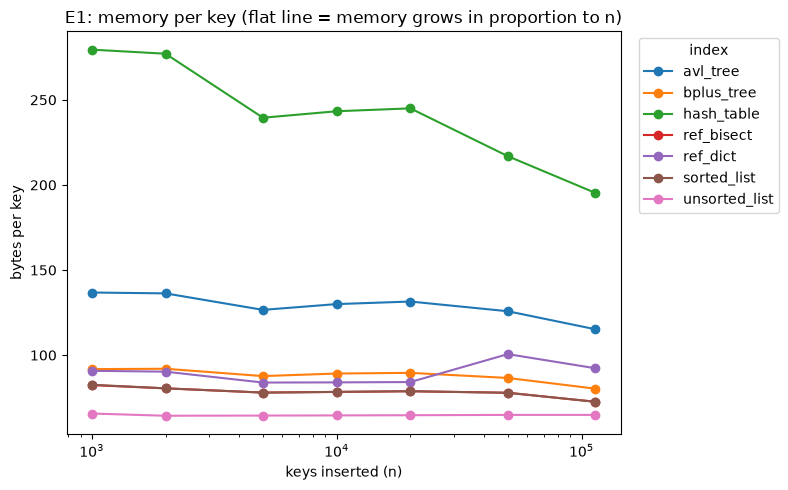

In [22]:
fig, ax = plt.subplots(figsize=(8, 5))
per_key.plot(ax=ax, marker="o", logx=True)
ax.set(xlabel="keys inserted (n)", ylabel="bytes per key",
       title="E1: memory per key (flat line = memory grows in proportion to n)")
ax.legend(title="index", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.savefig("e1_memory.png", dpi=150)
plt.show()

### Part E Q5: could RAM differences matter?

Docker VM memory on my machine is 7.75 GB (`machines.csv`). Divide by bytes per key at 114k to estimate how many keys each index could hold before running out (a rough upper bound: it ignores the Python process, the dataset itself and the OS).

In [23]:
DOCKER_GB = 7.75
bpk = per_key.loc[per_key.index.max()]
(pd.DataFrame({"bytes_per_key": bpk,
               "MB_at_114k": (mem.loc[mem.index.max()] / 1e6).round(2),
               "keys_that_fit_millions": (DOCKER_GB * 1e9 / bpk / 1e6).round(0)})
   .sort_values("bytes_per_key"))

,bytes_per_key,MB_at_114k,keys_that_fit_millions
index_type,,,
unsorted_list,64.9,7.40,119.0
ref_bisect,72.6,8.28,107.0
sorted_list,72.6,8.28,107.0
bplus_tree,80.3,9.15,97.0
ref_dict,92.3,10.52,84.0
avl_tree,115.2,13.14,67.0
hash_table,195.3,22.26,40.0


# E2: Point lookups (hits and misses)

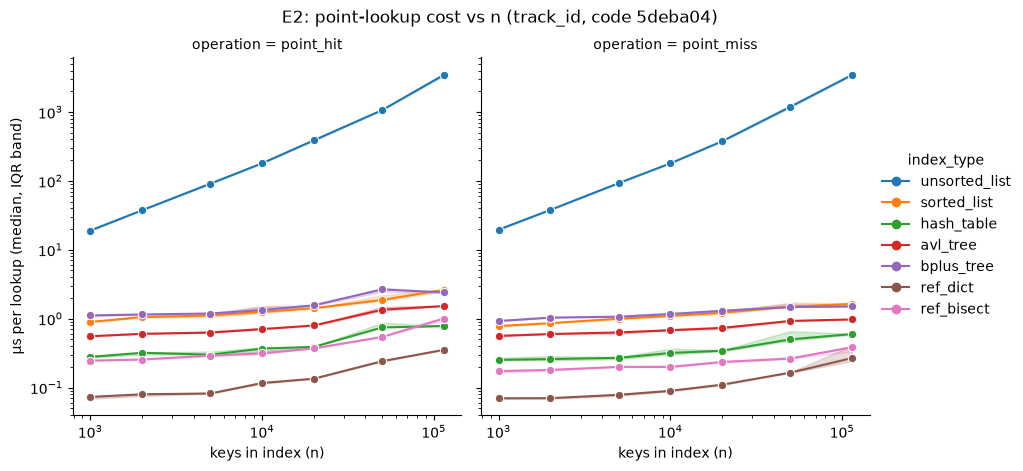

In [24]:
g = sns.relplot(data=e2, x="n_keys", y="us_per_op", hue="index_type", col="operation",
                kind="line", estimator="median", errorbar=("pi", 50), marker="o", height=4.5)
g.set(xscale="log", yscale="log", xlabel="keys in index (n)", ylabel="µs per lookup (median, IQR band)")
g.figure.suptitle(f"E2: point-lookup cost vs n (track_id, code {AFTER})", y=1.03)
g.savefig("e2_point_lookup_postfix.png", dpi=150)
plt.show()

In [25]:
(e2.groupby(["operation", "index_type", "n_keys"])["us_per_op"].median()
   .unstack("n_keys").round(3))

n_keys                    1000    2000    5000     10000    20000     50000   \
operation  index_type                                                          
point_hit  avl_tree        0.555   0.602   0.627    0.705    0.795     1.347   
           bplus_tree      1.112   1.148   1.187    1.331    1.561     2.652   
           hash_table      0.278   0.319   0.300    0.367    0.389     0.744   
           ref_bisect      0.246   0.255   0.291    0.313    0.370     0.542   
           ref_dict        0.073   0.080   0.082    0.116    0.134     0.241   
           sorted_list     0.895   1.052   1.112    1.251    1.416     1.868   
           unsorted_list  18.955  37.391  91.192  179.954  387.710  1064.799   
point_miss avl_tree        0.560   0.598   0.631    0.677    0.733     0.926   
           bplus_tree      0.924   1.035   1.067    1.163    1.302     1.475   
           hash_table      0.252   0.259   0.270    0.318    0.342     0.500   
           ref_bisect      0.173   0.180   0.199    0.199    0.235     0.263   
           ref_dict        0.070   0.070   0.078    0.090    0.110     0.164   
           sorted_list     0.781   0.859   0.998    1.092    1.219     1.495   
           unsorted_list  19.588  37.874  92.753  179.651  375.378  1195.540   

n_keys                      114000  
operation  index_type               
point_hit  avl_tree          1.521  
           bplus_tree        2.407  
           hash_table        0.781  
           ref_bisect        1.004  
           ref_dict          0.351  
           sorted_list       2.616  
           unsorted_list  3441.888  
point_miss avl_tree          0.974  
           bplus_tree        1.503  
           hash_table        0.597  
           ref_bisect        0.385  
           ref_dict          0.267  
           sorted_list       1.632  
           unsorted_list  3444.489

### Slopes of lookup cost vs n

Expected: about 1 for the unsorted list (full scan); small positive for the AVL tree, B+ tree and sorted list (O(log n));
about 0 in theory for the hash table and `ref_dict`. If those two rise together, that is CPU caching (a bigger table fits less well in cache), not the code.

In [26]:
e2_slopes = pd.DataFrame(
    [(idx, op, *slope_ci(g)) for (idx, op), g in e2.groupby(["index_type", "operation"])],
    columns=["index", "operation", "k", "ci_lo", "ci_hi"])
e2_slopes.pivot(index="index", columns="operation", values=["k", "ci_lo", "ci_hi"])

k                ci_lo                ci_hi           
operation     point_hit point_miss point_hit point_miss point_hit point_miss
index                                                                       
avl_tree           0.22       0.12      0.21       0.11      0.28       0.13
bplus_tree         0.19       0.11      0.17       0.10      0.21       0.12
hash_table         0.23       0.19      0.21       0.17      0.27       0.23
ref_bisect         0.27       0.15      0.26       0.13      0.28       0.18
ref_dict           0.34       0.28      0.33       0.23      0.36       0.34
sorted_list        0.21       0.16      0.19       0.14      0.23       0.20
unsorted_list      1.08       1.08      1.07       1.07      1.10       1.09

### Comparisons per lookup vs $\log_2$(distinct keys)

Counters are deterministic, so they have no noise. Trees and the sorted list should sit on the dashed line; the hash table should stay near 1 (hits) or below 1 (misses into short or empty buckets).

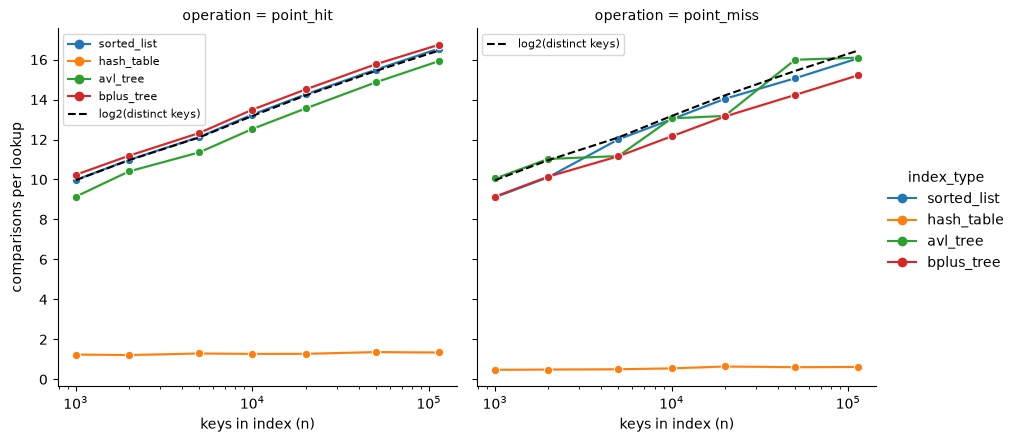

In [27]:
counted = e2[e2["comparisons"].notna() & (e2["index_type"] != "unsorted_list")]
g = sns.relplot(data=counted, x="n_keys", y="comparisons_per_op", hue="index_type",
                col="operation", kind="line", marker="o", height=4.5)
xs = np.array(sizes)
for ax in g.axes.flat:
    ax.plot(xs, np.log2([distinct[n] for n in xs]), "k--", label="log2(distinct keys)")
    ax.set(xscale="log", xlabel="keys in index (n)", ylabel="comparisons per lookup")
    ax.legend(loc="upper left", fontsize=8)
g.savefig("e2_comparisons_postfix.png", dpi=150)
plt.show()

### Hits vs misses

Ratio of miss cost to hit cost at each *n*. A tree or sorted-list miss still walks to the bottom; a hash-table miss stops at the end of one short bucket.

In [28]:
m = e2.groupby(["index_type", "n_keys", "operation"])["us_per_op"].median().unstack("operation")
(m["point_miss"] / m["point_hit"]).unstack("n_keys").round(2)

n_keys,1000,2000,5000,10000,20000,50000,114000
index_type,,,,,,,
avl_tree,1.01,0.99,1.01,0.96,0.92,0.69,0.64
bplus_tree,0.83,0.90,0.90,0.87,0.83,0.56,0.62
hash_table,0.90,0.81,0.90,0.86,0.88,0.67,0.76
ref_bisect,0.70,0.71,0.68,0.64,0.64,0.49,0.38
ref_dict,0.96,0.88,0.96,0.77,0.82,0.68,0.76
sorted_list,0.87,0.82,0.90,0.87,0.86,0.80,0.62
unsorted_list,1.03,1.01,1.02,1.00,0.97,1.12,1.00


### Fastest index at each n (crossovers)

C reference indexes left out, since they are not candidates.

In [29]:
main = e2[~e2["index_type"].str.startswith("ref_")]
for op, gop in main.groupby("operation"):
    med = gop.groupby(["n_keys", "index_type"])["us_per_op"].median().unstack()
    print(op)
    display(pd.DataFrame({
        "fastest": med.idxmin(axis=1),
        "µs": med.min(axis=1).round(3),
        "runner_up": med.apply(lambda r: r.nsmallest(2).index[1], axis=1),
        "runner_up_µs": med.apply(lambda r: r.nsmallest(2).iloc[1], axis=1).round(3),
    }))

point_hit


,fastest,µs,runner_up,runner_up_µs
n_keys,,,,
1000,hash_table,0.278,avl_tree,0.555
2000,hash_table,0.319,avl_tree,0.602
5000,hash_table,0.300,avl_tree,0.627
10000,hash_table,0.367,avl_tree,0.705
20000,hash_table,0.389,avl_tree,0.795
50000,hash_table,0.744,avl_tree,1.347
114000,hash_table,0.781,avl_tree,1.521


point_miss


,fastest,µs,runner_up,runner_up_µs
n_keys,,,,
1000,hash_table,0.252,avl_tree,0.560
2000,hash_table,0.259,avl_tree,0.598
5000,hash_table,0.270,avl_tree,0.631
10000,hash_table,0.318,avl_tree,0.677
20000,hash_table,0.342,avl_tree,0.733
50000,hash_table,0.500,avl_tree,0.926
114000,hash_table,0.597,avl_tree,0.974


### Python vs C: what the reference indexes show

Same big-O, different constant factor: the hash table vs `ref_dict`, and the sorted list vs `ref_bisect`.

In [30]:
def ratio(data, slow, fast, by):
    m = data.groupby(by + ["index_type"])["us_per_op"].median().unstack()
    return (m[slow] / m[fast]).round(1)

print("E2 lookups (Python / C):")
display(pd.DataFrame({
    "hash_table / ref_dict":     ratio(e2, "hash_table", "ref_dict", ["operation", "n_keys"]),
    "sorted_list / ref_bisect":  ratio(e2, "sorted_list", "ref_bisect", ["operation", "n_keys"]),
}).unstack("operation"))

print("E1 builds (Python / C):")
display(pd.DataFrame({
    "hash_table / ref_dict":     ratio(e1, "hash_table", "ref_dict", ["n_keys"]),
    "sorted_list / ref_bisect":  ratio(e1, "sorted_list", "ref_bisect", ["n_keys"]),
}))

E2 lookups (Python / C):


hash_table / ref_dict            sorted_list / ref_bisect           
operation             point_hit point_miss                point_hit point_miss
n_keys                                                                        
1000                        3.8        3.6                      3.6        4.5
2000                        4.0        3.7                      4.1        4.8
5000                        3.7        3.4                      3.8        5.0
10000                       3.2        3.5                      4.0        5.5
20000                       2.9        3.1                      3.8        5.2
50000                       3.1        3.0                      3.4        5.7
114000                      2.2        2.2                      2.6        4.2

E1 builds (Python / C):


,hash_table / ref_dict,sorted_list / ref_bisect
n_keys,,
1000,4.8,2.2
2000,5.3,2.7
5000,4.6,2.1
10000,4.6,1.6
20000,5.5,1.4
50000,4.5,1.2
114000,4.3,1.1


# Before vs after the bug fixes

At n = 114,000. Headline rows: hash table build (INC-03), AVL tree build (INC-02), sorted list lookups (INC-04).
Indexes that had no bug in between (B+ tree, the references, unsorted list) should have identical counters; any timing change for them is machine noise.

In [31]:
def before_after(data, before):
    big = data[data["n_keys"] == data["n_keys"].max()]
    t = (big.groupby(["index_type", "operation", "code_version"])[["us_per_op", "comparisons_per_op"]]
            .median().unstack("code_version"))
    out = pd.DataFrame({
        "us_before":  t[("us_per_op", before)],
        "us_after":   t[("us_per_op", AFTER)],
        "cmp_before": t[("comparisons_per_op", before)],
        "cmp_after":  t[("comparisons_per_op", AFTER)],
    })
    out["speedup"] = out["us_before"] / out["us_after"]
    return out.round(2)

print("E1 build (before = 0a4ba73)")
display(before_after(e1_all, E1_BEFORE))
print("E2 lookups (before = 67f1780)")
display(before_after(e2_all, E2_BEFORE))

E1 build (before = 0a4ba73)


,,us_before,us_after,cmp_before,cmp_after,speedup
index_type,operation,,,,,
avl_tree,build,10.61,5.51,16.45,15.31,1.93
bplus_tree,build,2.16,2.03,15.41,15.41,1.06
hash_table,build,21.03,0.77,0.87,0.71,27.47
ref_bisect,build,8.37,8.15,NaN,NaN,1.03
ref_dict,build,0.19,0.18,NaN,NaN,1.08
sorted_list,build,9.47,9.25,15.20,15.20,1.02
unsorted_list,build,0.09,0.09,0.00,0.00,1.03


E2 lookups (before = 67f1780)


us_before  us_after  cmp_before  cmp_after  speedup
index_type    operation                                                      
avl_tree      point_hit        1.68      1.52       15.93      15.93     1.10
              point_miss       1.02      0.97       16.10      16.10     1.05
bplus_tree    point_hit        2.63      2.41       16.75      16.75     1.09
              point_miss       1.53      1.50       15.22      15.22     1.02
hash_table    point_hit        0.81      0.78        1.28       1.34     1.04
              point_miss       0.66      0.60        0.75       0.62     1.11
ref_bisect    point_hit        1.00      1.00         NaN        NaN     1.00
              point_miss       0.39      0.38         NaN        NaN     1.01
ref_dict      point_hit        0.35      0.35         NaN        NaN     0.98
              point_miss       0.23      0.27         NaN        NaN     0.86
sorted_list   point_hit     3760.22      2.62    45380.81      16.55  1437.44
              point_miss    8758.46      1.63    84358.02      16.07  5367.80
unsorted_list point_hit     4072.27   3441.89   114000.00  114000.00     1.18
              point_miss    3957.22   3444.49   114000.00  114000.00     1.15

In [32]:
# Counters before vs after for the E1 build (resizes, rotations, height) at every n.
cnt = (e1_all[e1_all["index_type"].isin(["hash_table", "avl_tree"])]
       .groupby(["index_type", "n_keys", "code_version"])
       [["resizes", "rotations_per_op", "height"]].first()
       .unstack("code_version").round(3))
cnt

resizes                 rotations_per_op                  \
code_version      0a4ba73 5deba04 fdaa48d          0a4ba73 5deba04 fdaa48d   
index_type n_keys                                                            
avl_tree   1000       0.0     0.0     0.0            6.380   0.718   0.718   
           2000       0.0     0.0     0.0            7.338   0.704   0.704   
           5000       0.0     0.0     0.0            8.009   0.614   0.614   
           10000      0.0     0.0     0.0            9.592   0.648   0.648   
           20000      0.0     0.0     0.0           11.049   0.668   0.668   
           50000      0.0     0.0     0.0           12.296   0.620   0.620   
           114000     0.0     0.0     0.0           12.952   0.551   0.551   
hash_table 1000       2.0     8.0     8.0            0.000   0.000   0.000   
           2000       3.0     9.0     9.0            0.000   0.000   0.000   
           5000       6.0    10.0    10.0            0.000   0.000   0.000   
           10000     13.0    11.0    11.0            0.000   0.000   0.000   
           20000     25.0    12.0    12.0            0.000   0.000   0.000   
           50000     58.0    13.0    13.0            0.000   0.000   0.000   
           114000   117.0    14.0    14.0            0.000   0.000   0.000   

                   height                  
code_version      0a4ba73 5deba04 fdaa48d  
index_type n_keys                          
avl_tree   1000      14.0    12.0    12.0  
           2000      18.0    13.0    13.0  
           5000      17.0    14.0    14.0  
           10000     19.0    16.0    16.0  
           20000     22.0    17.0    17.0  
           50000     23.0    19.0    19.0  
           114000    23.0    20.0    20.0  
hash_table 1000       NaN     NaN     NaN  
           2000       NaN     NaN     NaN  
           5000       NaN     NaN     NaN  
           10000      NaN     NaN     NaN  
           20000      NaN     NaN     NaN  
           50000      NaN     NaN     NaN  
           114000     NaN     NaN     NaN

### Before/after plots for the incident reports

One plot per bug that shows up in E1/E2: INC-03 (hash table build), INC-02 (AVL tree build), INC-04 (sorted list lookups).

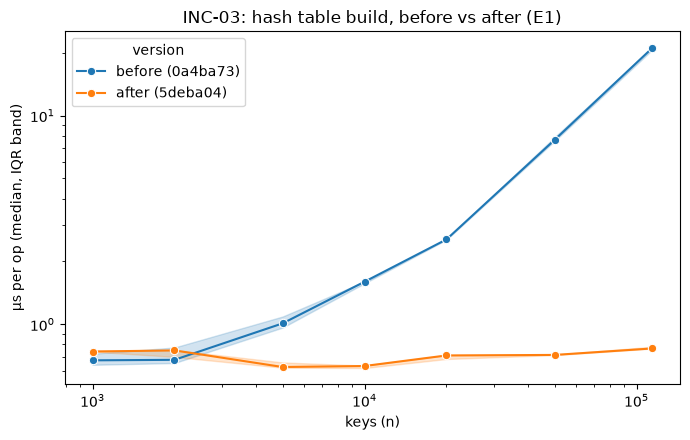

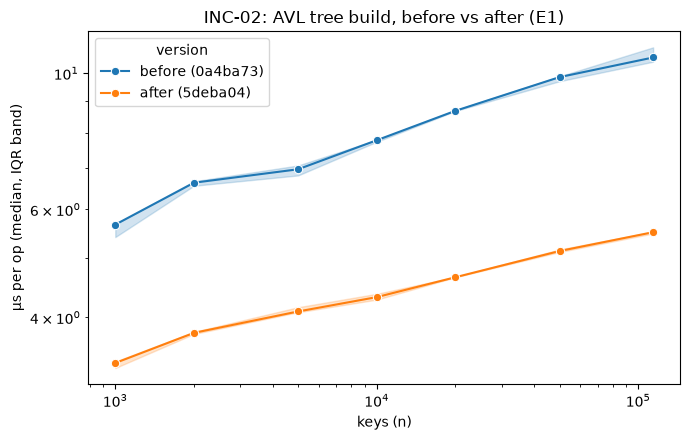

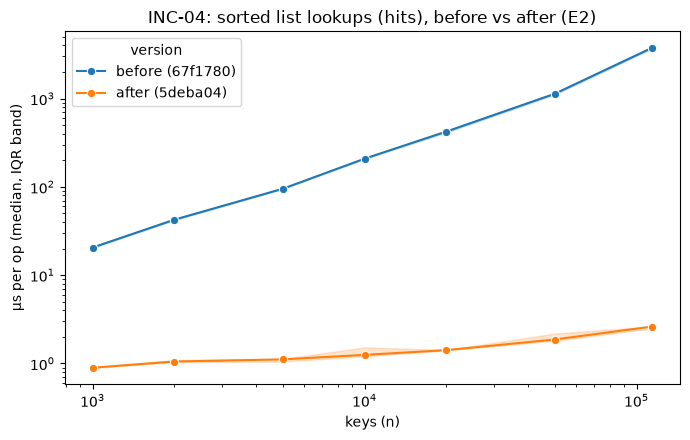

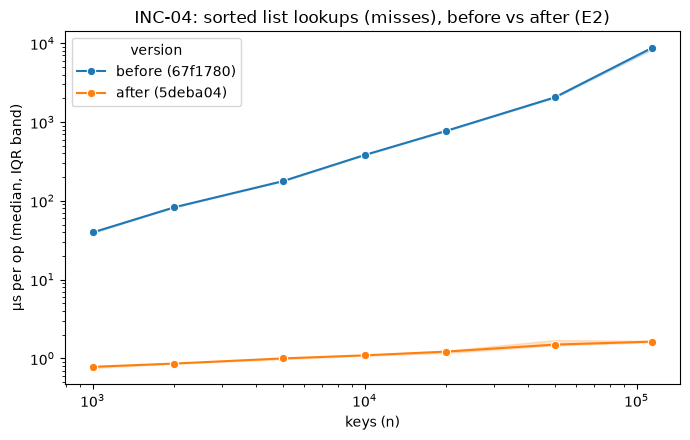

In [33]:
def before_after_plot(data, index_type, operation, before, title, fname):
    d = data[(data["index_type"] == index_type) & (data["operation"] == operation)].copy()
    d["version"] = d["code_version"].map({before: f"before ({before})", AFTER: f"after ({AFTER})"})
    fig, ax = plt.subplots(figsize=(7, 4.5))
    sns.lineplot(data=d, x="n_keys", y="us_per_op", hue="version",
                 estimator="median", errorbar=("pi", 50), marker="o", ax=ax)
    ax.set(xscale="log", yscale="log", xlabel="keys (n)",
           ylabel="µs per op (median, IQR band)", title=title)
    plt.tight_layout()
    plt.savefig(fname, dpi=150)
    plt.show()

before_after_plot(e1_all, "hash_table", "build", E1_BEFORE,
                  "INC-03: hash table build, before vs after (E1)", "e1_hash_build_before_after.png")
before_after_plot(e1_all, "avl_tree", "build", E1_BEFORE,
                  "INC-02: AVL tree build, before vs after (E1)", "e1_avl_build_before_after.png")
before_after_plot(e2_all, "sorted_list", "point_hit", E2_BEFORE,
                  "INC-04: sorted list lookups (hits), before vs after (E2)", "e2_sorted_hit_before_after.png")
before_after_plot(e2_all, "sorted_list", "point_miss", E2_BEFORE,
                  "INC-04: sorted list lookups (misses), before vs after (E2)", "e2_sorted_miss_before_after.png")

# Findings

All "after" numbers are from code `5deba04` (all fixes), machine `sanjay-mba`, 5 reps per configuration, medians reported. Replicates were stable: median CV was 1.8 to 8.1% per index.

**E1 build**
- **Slopes match big-O.** Per-insert cost is flat for the unsorted list (k = -0.04), hash table (0.01, 95% CI -0.00 to 0.02) and `ref_dict` (0.03), so inserts are O(1) amortized. The AVL tree (0.10) and B+ tree (0.11) have small positive slopes, which matches O(log n): log2 of the distinct-key count rises from 10 to 16.5 over this range, which predicts k ≈ 0.11.
- **Sorted list and `ref_bisect` per-insert cost grows with n** (k = 0.47 and 0.65 overall, steepening to about 0.6 to 0.7 between 50k and 114k) because every `list.insert` shifts the tail of the list. At 114k a sorted-list insert costs 9.25 µs vs 0.77 µs for the hash table.
- **Hash table resizes match doubling exactly** at every n (8 resizes at 1,000 keys up to 14 at 114,000).
- **AVL tree is properly balanced:** height 12 to 20, always under the 1.44 log2(d + 2) bound (14.4 to 23.7), with 0.55 to 0.72 rotations per insert.
- **B+ tree (order 32)** stays at height 3 to 4.

**E1 memory**
- **Memory grows in proportion to n** for every index (slopes 0.93 to 1.01).
- **Bytes per key falls with n for the indexes that group duplicates** (AVL 137 → 115, B+ tree 92 → 80, hash table 280 → 195, sorted list 83 → 73). A repeated `track_id` only appends a row id to an existing entry, and the share of distinct ids drops from 100% to 79% at 114k. The unsorted list stays flat (65 bytes/key) because it stores every pair separately. `ref_dict` jumps around (84 to 101 bytes/key) because of its own table-resize steps.
- **The hash table uses the most memory:** 22.3 MB at 114k (195 bytes/key), about 2x `ref_dict` (10.5 MB) and 2.4x the B+ tree (9.2 MB). The overhead is Python objects: every one of the 131,072 buckets is its own list object (about half of them empty), and every distinct key adds a `(key, values)` tuple plus a values list. `ref_dict` stores its entries in one compact C array.
- **Part E Q5:** the largest index needs 22.3 MB, about 350x less than the 7.75 GB Docker memory on my machine, so RAM differences between our machines cannot affect these results. As a rough upper bound (ignoring the Python process, the dataset and the OS), the hash table would hit the Docker limit at around 40 million keys, and the leanest index (unsorted list) at around 119 million.

**E2 lookups**
- **Unsorted list is linear,** as expected: slope 1.08 for hits and misses, 3,442 µs per lookup at 114k. Hits cost the same as misses because its search collects every match, so it scans all n entries either way (114,000 comparisons per lookup).
- **Trees and sorted list:** slopes 0.11 to 0.22. Comparisons per lookup at 114k (AVL 15.9, B+ tree 16.8, sorted list 16.6) sit on log2(89,741 distinct keys) = 16.5, confirming O(log n).
- **Hash table and `ref_dict`** rise with n (slopes 0.19 to 0.34) even though hash comparisons stay flat (about 1.3 per hit, 0.6 per miss). The extra time is not extra work. Every index jumps between 20k and 50k keys, most clearly for hits (1.3 to 1.9x for a 2.5x increase in n, vs 1.06 to 1.18x from 10k to 20k), which is consistent with the data outgrowing a CPU cache level.
- **Misses are cheaper than hits for the ordered indexes at large n** (miss/hit time ratio 0.6 to 0.8 at 114k) even though their comparison counts are nearly identical. So the gap is in the cost of each comparison, not in the number of comparisons. Likely causes are shorter string comparisons (misses are random strings, so a comparison usually stops at the first or second character, while a hit ends with a full 22-character equality check) or memory access patterns. These runs cannot tell the two apart.
- **The hash table is the fastest candidate at every n,** for both hits and misses, so there is no crossover. At 114k: 0.78 µs per hit and 0.60 µs per miss, about 2x faster than the runner-up AVL tree (1.52 / 0.97 µs).
- **Python vs C:** same big-O, different constant factor. The hash table is 2.2 to 4.0x slower than `ref_dict` for lookups and 4.3 to 5.5x for builds. Sorted-list lookups are 2.6 to 5.7x slower than `ref_bisect`, but sorted-list builds converge to 1.1x at 114k, because the C memmove that shifts the list dominates both.

**Before vs after (n = 114,000)**
- **INC-03 hash table build:** 21.03 → 0.77 µs per insert (27x faster). Before the fix, `_grow` added a fixed 1,024 buckets instead of doubling, so the table resized every 768 new distinct keys (0.75 × 1,024): 117 resizes at 114k, each one rehashing every stored key, so the total rehashing work was quadratic. After the fix, the table doubles and resizes follow log2 (14).
- **INC-02 AVL tree build:** 10.61 → 5.51 µs per insert (1.9x). Before the fix, both rotation functions updated the parent's height before the child's, so the stored heights came out too large and triggered unnecessary rotations. Rotations per insert fell from 12.95 to 0.55. A correct AVL insert needs at most one rebalance (a double rotation counts as 2 rotations), so 13 per insert was wasted work. Height fell from 23 to 20 (both within the 23.7 bound on this data; the bound violation shows up in E5's synthetic keys).
- **INC-04 sorted list lookups:** hits 3,760 → 2.62 µs (1,437x), misses 8,758 → 1.63 µs (5,368x). Comparisons per lookup fell from 45,381 (hits) and 84,358 (misses), which is linear-scan behavior, to 16.6 and 16.1, which is binary search at log2(89,741) = 16.5.
- **Code with no fix between the two versions** (E1: B+ tree and sorted-list build, since INC-04 only changed `search`; E2: AVL and B+ tree, already fixed in `67f1780`; both: unsorted list and the references) has identical counters. Their timing differences (0.86x to 1.18x) are run-to-run machine variation, not code changes. Hash-table lookup counters shift slightly (1.28 → 1.34 per hit) only because the fixed table ends at a different bucket count.

**Recommendation for F1 (track page): hash table.**
It is the fastest candidate for both hits and stale-link misses at every catalog size, its comparisons stay flat as the catalog grows, and its build cost after the fix is low (0.77 µs per insert). The trade-offs: it uses the most memory (22.3 MB at 114k, still tiny next to available RAM), and it cannot answer range or prefix queries. That does not matter for F1, which only ever looks up one exact `track_id`. If ordered access were ever needed on the same index, the AVL tree is the runner-up (about 2x slower).
